## 1. Setup and load data

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_validate, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FEATURE_DIR = PROCESSED_DIR / "features"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

feature_df = pd.read_csv(PROCESSED_DIR / "extracted_features.csv")

train_actors = pd.read_csv(FEATURE_DIR / "train_actors.csv").squeeze("columns")
test_actors = pd.read_csv(FEATURE_DIR / "test_actors.csv").squeeze("columns")

train_actor_ids = set(train_actors.unique())
test_actor_ids = set(test_actors.unique())

metadata_columns = [
    "recording_id", "file_path", "actor_id", "emotion_id",
    "emotion_label", "intensity", "statement_id", "repetition"
]

train_data = feature_df[feature_df["actor_id"].isin(train_actor_ids)].copy()
test_data = feature_df[feature_df["actor_id"].isin(test_actor_ids)].copy()

X_train = train_data.drop(columns=metadata_columns)
X_test = test_data.drop(columns=metadata_columns)

y_train = train_data["emotion_label"]
y_test = test_data["emotion_label"]

groups_train = train_data["actor_id"]

feature_columns = X_train.columns.tolist()
labels = sorted(y_train.unique())

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training speakers:", sorted(train_actor_ids))
print("Testing speakers:", sorted(test_actor_ids))
print("Emotion classes:", labels)

Training data: (1140, 53)
Testing data: (300, 53)
Training speakers: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Testing speakers: [np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]
Emotion classes: ['Angry', 'Calm', 'Disgust', 'Fearful', 'Happy', 'Neutral', 'Sad', 'Surprised']


## 2. Define model pipelines

The feature CSV contains the **raw extracted features**. We deliberately rebuild the split using the actor IDs saved in Notebook 03 rather than loading the already-scaled matrices.

Each pipeline learns its imputation and scaling parameters only from the training portion of each cross-validation fold.

- Logistic Regression, SVM and KNN: median imputation + standardization.
- Random Forest: median imputation; scaling is not required for tree models.

In [3]:
def make_scaled_pipeline(classifier):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])


def make_tree_pipeline(classifier):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", classifier)
    ])


models = {
    "Logistic Regression": make_scaled_pipeline(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Linear SVM": make_scaled_pipeline(
        SVC(
            kernel="linear",
            class_weight="balanced",
            random_state=42
        )
    ),

    "RBF SVM": make_scaled_pipeline(
        SVC(
            kernel="rbf",
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": make_tree_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    ),

    "KNN": make_scaled_pipeline(
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="minkowski",
            p=2,
            n_jobs=-1
        )
    )
}

## 3. Compare baseline models with speaker-independent cross-validation

`GroupKFold` ensures that each validation fold contains speakers not used to train that fold. We use weighted F1 as the main comparison metric and also record accuracy and macro F1.

In [4]:
group_cv = GroupKFold(n_splits=5)

scoring = {
    "accuracy": "accuracy",
    "weighted_f1": "f1_weighted",
    "macro_f1": "f1_macro"
}

baseline_rows = []

for model_name, model in models.items():
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    baseline_rows.append({
        "Model": model_name,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Weighted F1": cv_scores["test_weighted_f1"].mean(),
        "CV Macro F1": cv_scores["test_macro_f1"].mean()
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "CV Weighted F1",
    ascending=False
).reset_index(drop=True)

baseline_results

,Model,CV Accuracy,CV Weighted F1,CV Macro F1
0,RBF SVM,0.492500,0.483622,0.474740
1,Random Forest,0.481111,0.466871,0.450004
2,Linear SVM,0.468889,0.457962,0.444528
3,Logistic Regression,0.458611,0.452346,0.443973
4,KNN,0.369722,0.366550,0.358645


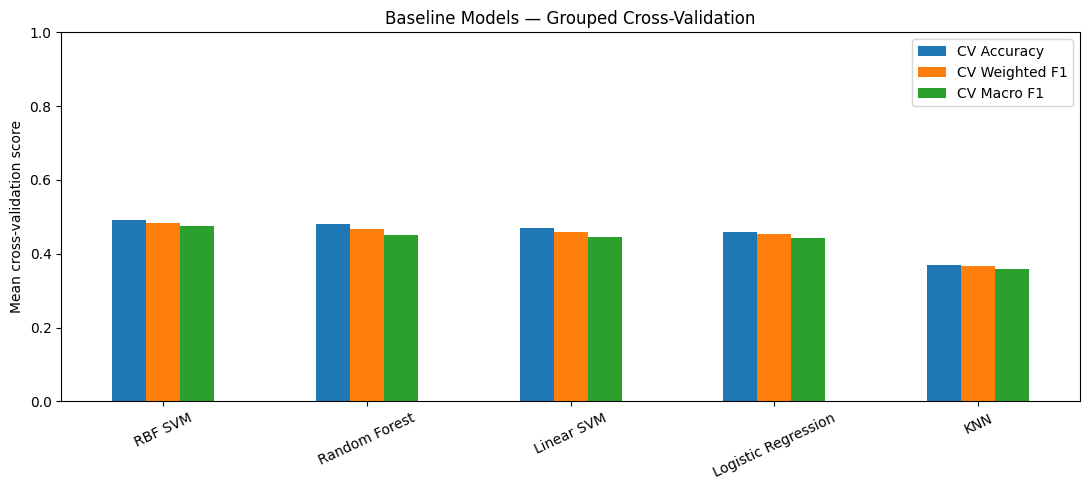

In [5]:
baseline_results.set_index("Model")[
    ["CV Accuracy", "CV Weighted F1", "CV Macro F1"]
].plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=25)

plt.title("Baseline Models — Grouped Cross-Validation")
plt.ylabel("Mean cross-validation score")
plt.xlabel("")
plt.tight_layout()
plt.show()

## 4. Tune the strongest candidate families

We tune RBF SVM and Random Forest using the same grouped folds. The preprocessing steps remain inside the pipelines, so each fold learns its own imputation and scaling parameters.

In [6]:
svm_pipeline = make_scaled_pipeline(
    SVC(kernel="rbf", class_weight="balanced", random_state=42)
)

svm_param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_weighted",
    cv=group_cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

svm_search.fit(X_train, y_train, groups=groups_train)

print("Best RBF SVM parameters:", svm_search.best_params_)
print(f"Best grouped CV weighted F1: {svm_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best RBF SVM parameters: {'classifier__C': 1, 'classifier__gamma': 0.01}
Best grouped CV weighted F1: 0.4884


In [7]:
rf_pipeline = make_tree_pipeline(
    RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )
)

rf_param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 20],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", 0.5]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1_weighted",
    cv=group_cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

rf_search.fit(X_train, y_train, groups=groups_train)

print("Best Random Forest parameters:", rf_search.best_params_)
print(f"Best grouped CV weighted F1: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Random Forest parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 400}
Best grouped CV weighted F1: 0.4680


## 5. Select the model using cross-validation results

Model selection is based on grouped cross-validation on the training speakers, not on the held-out test set.

In [8]:
candidate_scores = {
    row["Model"]: row["CV Weighted F1"]
    for _, row in baseline_results.iterrows()
}

candidate_models = dict(models)

candidate_scores["Tuned RBF SVM"] = svm_search.best_score_
candidate_models["Tuned RBF SVM"] = svm_search.best_estimator_

candidate_scores["Tuned Random Forest"] = rf_search.best_score_
candidate_models["Tuned Random Forest"] = rf_search.best_estimator_

cv_comparison = pd.DataFrame([
    {"Model": name, "CV Weighted F1": score}
    for name, score in candidate_scores.items()
]).sort_values(
    "CV Weighted F1",
    ascending=False
).reset_index(drop=True)

cv_comparison

,Model,CV Weighted F1
0,Tuned RBF SVM,0.488399
1,RBF SVM,0.483622
2,Tuned Random Forest,0.468005
3,Random Forest,0.466871
4,Linear SVM,0.457962
5,Logistic Regression,0.452346
6,KNN,0.366550


In [9]:
best_model_name = cv_comparison.iloc[0]["Model"]

# GridSearchCV already refits its winning estimator on all training data.
# Baseline candidates are fitted on all training data here.
if best_model_name in {"Tuned RBF SVM", "Tuned Random Forest"}:
    best_model = candidate_models[best_model_name]
else:
    best_model = clone(candidate_models[best_model_name])
    best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)
print(f"Grouped CV weighted F1: {candidate_scores[best_model_name]:.4f}")

Selected model: Tuned RBF SVM
Grouped CV weighted F1: 0.4884


## 6. Final evaluation on held-out speakers

The test speakers have not participated in model training, cross-validation or hyperparameter selection. Evaluate the selected model once on this held-out set.

In [10]:
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_weighted_f1 = f1_score(y_test, y_pred, average="weighted")
test_macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Selected model:", best_model_name)
print(f"Test accuracy:    {test_accuracy:.4f}")
print(f"Test weighted F1: {test_weighted_f1:.4f}")
print(f"Test macro F1:    {test_macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

Selected model: Tuned RBF SVM
Test accuracy:    0.4967
Test weighted F1: 0.4971
Test macro F1:    0.4914

Classification report:
              precision    recall  f1-score   support

       Angry       0.81      0.62      0.70        40
        Calm       0.45      0.78      0.57        40
     Disgust       0.52      0.38      0.43        40
     Fearful       0.42      0.55      0.48        40
       Happy       0.62      0.38      0.47        40
     Neutral       0.29      0.70      0.41        20
         Sad       0.43      0.30      0.35        40
   Surprised       0.83      0.38      0.52        40

    accuracy                           0.50       300
   macro avg       0.55      0.51      0.49       300
weighted avg       0.56      0.50      0.50       300



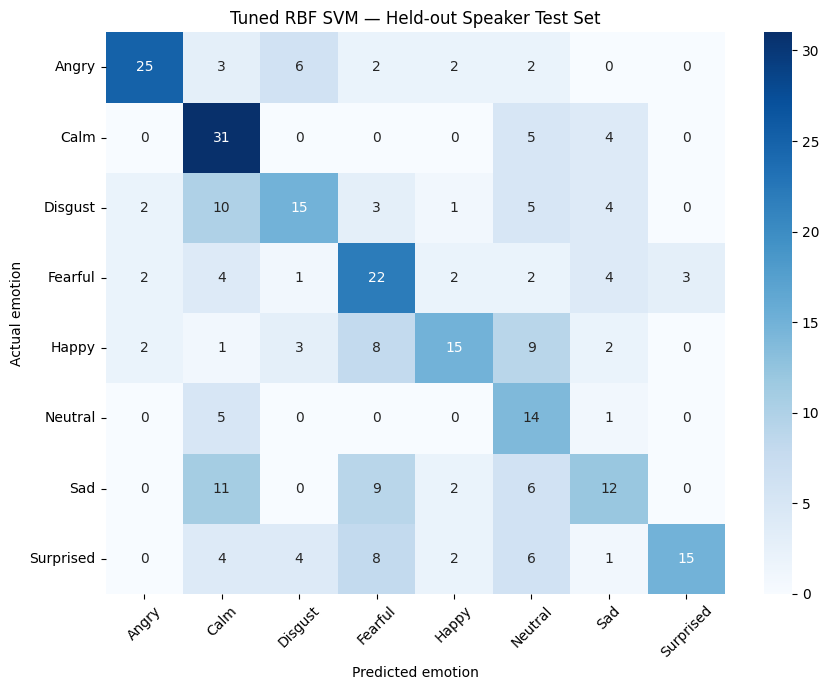

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f"{best_model_name} — Held-out Speaker Test Set")
plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Save final model and results

The selected model is saved as a complete scikit-learn pipeline. It includes its imputation and scaling steps, so inference must pass the **raw extracted feature values** in the same column order.

In [12]:
joblib.dump(
    best_model,
    MODEL_DIR / "best_traditional_model.pkl"
)

joblib.dump(
    feature_columns,
    MODEL_DIR / "traditional_feature_columns.pkl"
)

cv_comparison.to_csv(
    RESULTS_DIR / "traditional_ml_cv_comparison.csv",
    index=False
)

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "best_traditional_model_report.csv"
)

pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv(
    RESULTS_DIR / "best_traditional_model_confusion_matrix.csv"
)

final_metrics = {
    "selected_model": best_model_name,
    "cv_weighted_f1": float(candidate_scores[best_model_name]),
    "test_accuracy": float(test_accuracy),
    "test_weighted_f1": float(test_weighted_f1),
    "test_macro_f1": float(test_macro_f1),
    "feature_count": len(feature_columns),
    "emotion_classes": labels
}

with open(RESULTS_DIR / "traditional_ml_summary.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

print("Saved selected model and evaluation results.")

Saved selected model and evaluation results.
